# Phase 4: multi-step agent, recovery paths, one round of expert iteration (Colab T4)
Stages (each is skip-if-done, so a disconnect loses nothing; each prints a time estimate; target about 60 min on a T4):
1. fine-tuned Qwen agent **without** recovery on the 174 test episodes
2. fine-tuned Qwen agent **with** recovery
3. expert-iteration rollouts on training episodes (sampling, temperature 0.8, recovery on, the simulator is the reward)
4. build the RL dataset from simulator-verified successes, mixed with the Phase 2 train set
5. continue LoRA fine-tuning from the Phase 3 adapter (1 epoch, lr 1e-4)
6. single-step eval of the new model, then the agent with recovery on the test episodes
7. results tables + a results zip (no weights)

**Needs:** the Phase 3 adapter on Drive at `runs/phase3/qwen25_05b_lora/adapter` (written by notebook 01), and your latest code **pushed to GitHub**.
**Data** comes from the git clone; **runs** are written to Drive under `runs/phase4/`; the last cell writes `runs/phase4_results.zip` (download it from drive.google.com, then `python scripts/import_results_zip.py <zip>` on the Mac).

**Kernel:** in VS Code choose **Select Kernel -> Colab -> New Colab Server -> GPU -> T4**. If Colab disconnects: reconnect and run all cells again.

In [1]:
# ===== CONFIG: change settings here only =====
CONFIG = dict(
    base_model="Qwen/Qwen2.5-0.5B-Instruct",
    phase3_run="qwen25_05b_lora",      # the adapter to start from (runs/phase3/<this>/adapter)
    rl_run="qwen25_05b_rl",            # new run (runs/phase4/<this>)
    max_steps=8,
    # expert iteration
    n_train_episodes=704,              # seeded subset of the 1408 train episodes (all = 1408; time scales linearly)
    samples_per_episode=2,             # k rollouts per episode
    temperature=0.8,
    chunk_episodes=176,                # rollouts are saved in chunks of this many episodes
    rl_learning_rate=1e-4, rl_epochs=1,
    eval_batch_size=64,                # prompts per generate() call
)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os, subprocess
REPO = "/content/spice-verified-analog-finetuning"
if os.path.isdir(REPO):
    subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
    subprocess.run(["git", "clone", "https://github.com/Keerthanareddy17/spice-verified-analog-finetuning.git", REPO], check=True)
os.chdir(REPO)
print(subprocess.run(["git", "log", "-1", "--oneline"], capture_output=True, text=True).stdout)

f966a4e Phase 4: multi-step agent, tracing and recovery, expert iteration, Colab notebook



In [4]:
# torch comes preinstalled on Colab: do not reinstall it. This notebook also needs ngspice (the agent simulates every move).
# Colab ships an old torchao (0.10.0) that we never use; peft 0.21.2 aborts LoRA creation when it finds torchao < 0.16.
!pip -q uninstall -y torchao
!pip -q install -r requirements-colab.txt
!pip -q install -e . --no-deps
!apt-get -qq install -y ngspice > /dev/null
!ngspice --version | head -3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 119.7 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 948.2/948.2 kB 48.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 59.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 15.8 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for analogft (pyproject.toml) ... done
******
** ngspice-42 : Circuit level s

In [5]:
# Fail early, before any model loads: print versions and run peft's optional-package checks (the torchao check is what broke before).
import importlib, importlib.metadata as md, importlib.util
importlib.invalidate_caches()
for pkg in ["torch", "transformers", "trl", "peft", "accelerate", "datasets", "torchao", "bitsandbytes"]:
    try:
        print(f"{pkg:14s}", md.version(pkg))
    except md.PackageNotFoundError:
        print(f"{pkg:14s}", "not installed")
import peft.import_utils as piu
from peft import get_peft_model, LoraConfig   # noqa: F401
bad = []
for name in sorted(n for n in dir(piu) if n.startswith("is_") and n.endswith("_available")):
    try:
        getattr(piu, name)()
    except ImportError as e:
        bad.append(f"{name}: {e}")
    except TypeError:
        pass   # needs arguments, not an environment check
assert not bad, "peft found an incompatible optional package:\n" + "\n".join(bad)
print("peft optional-package checks OK")

torch          2.11.0+cu130
transformers   5.20.0
trl            1.16.0
peft           0.21.2
accelerate     1.15.0
datasets       5.1.0
torchao        not installed
bitsandbytes   not installed
peft optional-package checks OK


In [6]:
import sys
sys.path.insert(0, REPO + "/src")
import importlib, transformers, trl, peft, torch
from analogft import paths
from analogft.drive_check import verify_manifest
print("colab:", paths.IS_COLAB, "| data:", paths.DATA_DIR, "| runs:", paths.RUNS_DIR)
print("transformers", transformers.__version__, "| trl", trl.__version__, "| peft", peft.__version__, "| torch", torch.__version__)
ok, problems = verify_manifest(paths.DATA_DIR)
assert ok, "data/ in the repo clone does not match data/manifest.json (did you push the data commit? run git pull): " + "; ".join(problems[:5])
print("data manifest OK (data read from the git clone:", paths.DATA_DIR, ")")

colab: True | data: /content/spice-verified-analog-finetuning/data | runs: /content/drive/MyDrive/spice-verified-analog-finetuning/runs
transformers 5.20.0 | trl 1.16.0 | peft 0.21.2 | torch 2.11.0+cu130
data manifest OK (data read from the git clone: /content/spice-verified-analog-finetuning/data )


In [7]:
import torch
if not torch.cuda.is_available():
    raise SystemExit("NO GPU: in VS Code use Select Kernel -> Colab -> New Colab Server -> GPU -> T4, then run all cells again.")
print("GPU:", torch.cuda.get_device_name(0), "| memory GB:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

GPU: Tesla T4 | memory GB: 15.6


In [8]:
# The Colab ngspice must reproduce the Mac's answer for the nominal design (results/reference_nominal.json).
import json, os
from analogft.circuit import nominal_design, simulate
ref = json.load(open(paths.REPO_ROOT / "results" / "reference_nominal.json"))
r = simulate(nominal_design(), use_cache=False)
for k, v in ref["metrics"].items():
    got = r.metrics[k]
    assert abs(got - v) <= 1e-3 * abs(v) + 1e-12, f"ngspice disagrees with the Mac on {k}: {got} vs {v}"
print("ngspice matches the Mac reference:", {k: round(r.metrics[k], 4) for k in ("dc_gain_db", "pm_deg")}, "| cpus:", os.cpu_count())

ngspice matches the Mac reference: {'dc_gain_db': 74.205, 'pm_deg': 67.7666} | cpus: 2


In [9]:
import time
from pathlib import Path
from analogft.agent import SimPool
from analogft.agent_eval import fmt_agent, load_episodes, run_and_save, seeded_subset
from analogft.dataset import read_jsonl
from analogft.expert_iteration import build_rl_dataset
from analogft.finetune import FTConfig, evaluate_model, train
from analogft.phase4_run import load_rollouts, run_rollouts, write_rollouts_summary
from analogft.policies import LLMPolicy
from analogft.predict import HFBackend

P4 = paths.RUNS_DIR / "phase4"
ADAPTER3 = paths.RUNS_DIR / "phase3" / CONFIG["phase3_run"] / "adapter"
assert (ADAPTER3 / "adapter_config.json").exists(), f"Phase 3 adapter not found at {ADAPTER3}: run notebook 01 first"
test_eps, train_eps = load_episodes("test"), load_episodes("train")
sim = SimPool(workers=max(2, os.cpu_count() or 2))
t_sim = time.time(); sim.run([nominal_design()] * 1); print("simulation pool ready;", len(test_eps), "test episodes,", len(train_eps), "train episodes")
backend = HFBackend(CONFIG["base_model"], ADAPTER3, batch_size=CONFIG["eval_batch_size"])   # greedy by default
policy = LLMPolicy(backend, name="finetuned_qwen")

simulation pool ready; 174 test episodes, 1408 train episodes


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

## 1. Fine-tuned agent WITHOUT recovery (174 test episodes)

In [10]:
m_ft0 = run_and_save(P4 / "agents" / "ft_norecovery", "ft_norecovery", policy, test_eps, recovery=False, sim=sim, skip_if_done=True, max_steps=CONFIG["max_steps"])
print(fmt_agent(m_ft0))

[ft_norecovery] step 1/8: 174 active, 48/174 solved, step took 21.9s, total 24s
[ft_norecovery] step 2/8: 126 active, 93/174 solved, step took 14.0s, total 38s
[ft_norecovery] step 3/8: 81 active, 117/174 solved, step took 11.2s, total 49s
[ft_norecovery] step 4/8: 57 active, 128/174 solved, step took 6.6s, total 56s
[ft_norecovery] step 5/8: 46 active, 134/174 solved, step took 5.7s, total 61s
[ft_norecovery] step 6/8: 40 active, 136/174 solved, step took 5.3s, total 67s
[ft_norecovery] step 7/8: 38 active, 136/174 solved, step took 5.2s, total 72s
[ft_norecovery] step 8/8: 38 active, 136/174 solved, step took 5.1s, total 77s
n=174 success=0.782 [0.718, 0.845] median_steps=2.0 final_dist=0.026 sims/ep=2.3 invalid=0.000 recoveries/ep=0.00


## 2. Fine-tuned agent WITH recovery

In [11]:
m_ft1 = run_and_save(P4 / "agents" / "ft_recovery", "ft_recovery", policy, test_eps, recovery=True, sim=sim, skip_if_done=True, max_steps=CONFIG["max_steps"])
print(fmt_agent(m_ft1))

[ft_recovery] step 1/8: 174 active, 48/174 solved, step took 19.2s, total 19s
[ft_recovery] step 2/8: 126 active, 99/174 solved, step took 17.4s, total 37s
[ft_recovery] step 3/8: 75 active, 126/174 solved, step took 14.3s, total 51s
[ft_recovery] step 4/8: 48 active, 140/174 solved, step took 9.8s, total 61s
[ft_recovery] step 5/8: 34 active, 149/174 solved, step took 9.0s, total 70s
[ft_recovery] step 6/8: 23 active, 153/174 solved, step took 8.2s, total 78s
[ft_recovery] step 7/8: 19 active, 157/174 solved, step took 8.3s, total 86s
[ft_recovery] step 8/8: 15 active, 157/174 solved, step took 7.7s, total 94s
n=174 success=0.902 [0.856, 0.948] median_steps=2 final_dist=0.011 sims/ep=2.9 invalid=0.000 recoveries/ep=0.67


## 3. Expert-iteration rollouts on TRAIN episodes (sampling; chunked and resumable; prints a time estimate)

In [12]:
sub_train = seeded_subset(train_eps, CONFIG["n_train_episodes"], seed=0)
print(f"{len(sub_train)} train episodes x {CONFIG['samples_per_episode']} samples at temperature {CONFIG['temperature']}")
backend.temperature = CONFIG["temperature"]
run_rollouts(policy, sub_train, P4 / "rollouts", sim, samples=CONFIG["samples_per_episode"], chunk_size=CONFIG["chunk_episodes"])
backend.temperature = 0.0
roll_steps, roll_eps = load_rollouts(P4 / "rollouts")
print(write_rollouts_summary(P4 / "rollouts", roll_eps, P4 / "rollouts_summary.json", CONFIG["samples_per_episode"], CONFIG["temperature"]))

704 train episodes x 2 samples at temperature 0.8
  [rollout00] step 1/8: 352 active, 109/352 solved, step took 46.9s, total 49s
  [rollout00] step 2/8: 243 active, 181/352 solved, step took 38.0s, total 87s
  [rollout00] step 3/8: 171 active, 232/352 solved, step took 28.7s, total 115s
  [rollout00] step 4/8: 120 active, 274/352 solved, step took 23.4s, total 139s
  [rollout00] step 5/8: 77 active, 295/352 solved, step took 19.6s, total 158s
  [rollout00] step 6/8: 56 active, 307/352 solved, step took 11.1s, total 170s
  [rollout00] step 7/8: 44 active, 314/352 solved, step took 10.3s, total 180s
  [rollout00] step 8/8: 36 active, 319/352 solved, step took 12.6s, total 192s
[rollouts] chunk 1/4: 352 rollouts, 319 solved, 192s; about 9.6 min left
  [rollout01] step 1/8: 352 active, 97/352 solved, step took 48.1s, total 50s
  [rollout01] step 2/8: 255 active, 183/352 solved, step took 37.7s, total 88s
  [rollout01] step 3/8: 169 active, 228/352 solved, step took 29.0s, total 117s
  [rol

## 4. RL dataset: only simulator-verified successes, improving steps the model chose itself (no rules fallback), no duplicates; mixed with the Phase 2 train set

In [13]:
(P4 / "rl_dataset").mkdir(parents=True, exist_ok=True)
phase2_train = read_jsonl(paths.DATA_DIR / "phase2" / "train.jsonl")
mixed, rl_stats = build_rl_dataset(phase2_train, roll_steps, roll_eps, P4 / "rl_dataset" / "rl_train.jsonl", seed=0)
import json
print(json.dumps(rl_stats, indent=1))
assert rl_stats["new_examples"] > 0, "no new examples: nothing to learn from (see the stats above)"

{
 "rollouts": 1408,
 "rollouts_solved": 1293,
 "rollout_success_rate": 0.9183238636363636,
 "steps_total": 4219,
 "candidate_steps": 3002,
 "dropped": {
  "no_improvement_detour": 295,
  "episode_not_solved": 908,
  "rules_fallback_step": 14
 },
 "duplicates_of_phase2_train": 1196,
 "new_examples": 1579,
 "train_examples_before": 2926,
 "train_examples_after": 4505,
 "new_by_step_index": {
  "0": 303,
  "1": 436,
  "2": 347,
  "3": 235,
  "4": 124,
  "5": 78,
  "6": 37,
  "7": 19
 },
 "new_by_action": {
  "cc_down": 323,
  "ibias_down": 316,
  "cc_up": 197,
  "w_in_up": 144,
  "w_cs_up": 136,
  "l_in_up": 122,
  "out_ratio_down": 90,
  "l_in_down": 86,
  "ibias_up": 76,
  "w_in_down": 40,
  "out_ratio_up": 27,
  "l_load_down": 15,
  "l_load_up": 5,
  "w_cs_down": 2
 }
}


## 5. Continue fine-tuning from the Phase 3 adapter (1 epoch, lr 1e-4, same LoRA config and fp16 handling)

In [14]:
import gc, torch
del backend, policy; gc.collect(); torch.cuda.empty_cache()
cfg_rl = FTConfig(base_model=CONFIG["base_model"], run_name=CONFIG["rl_run"], phase="phase4", init_adapter=str(ADAPTER3),
                  train_file=str(P4 / "rl_dataset" / "rl_train.jsonl"), epochs=CONFIG["rl_epochs"],
                  learning_rate=CONFIG["rl_learning_rate"], per_device_batch=16, grad_accum=1)
if (cfg_rl.run_dir / "adapter" / "adapter_config.json").exists():
    print("RL adapter already trained:", cfg_rl.run_dir / "adapter")
else:
    rl_summary = train(cfg_rl)

conversation length in tokens: {'n': 4883, 'max': 550, 'mean': 525.3346303501945}
train=4505 val=378 precision=fp16 (requested auto)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Tokenizing train dataset:   0%|          | 0/4505 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/4505 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/4505 [00:00<?, ? examples/s]

...

Truncating eval dataset:   0%|          | 0/378 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/378 [00:00<?, ? examples/s]

trainable parameters: 8,798,208
masking check (example 0): 526 tokens, 46 with loss, 480 masked
  masked tail of prompt : '30%<|im_end|>\n<|im_start|>assistant\n'
  tokens WITH loss      : '{"action": "cc_up", "reason": "PM 53.1 < 66 deg is the largest shortfall; cc_up: PM +5.7 deg, UGF -18%"}<|im_end|>\n'


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,0.122900,0.116501,0.118759,0.954620,420065.000000
100,0.113336,0.113046,0.106948,0.954325,840332.000000
150,0.110552,0.113055,0.113222,0.954417,1261055.000000
200,0.103321,0.112179,0.103257,0.955166,1681795.000000
250,0.090260,0.108347,0.103839,0.957580,2101793.000000
282,0.106913,0.108066,0.103664,0.957422,2366989.000000


[timing] 3.08 s/step -> about 13.5 min of training left (282 steps total, evals/checkpoints extra)
training done: {'train_minutes': 15.36, 'final_train_loss': 0.10771422415760391, 'fp16': True, 'global_step': 282, 'tokens': 526, 'loss_tokens': 46, 'final_eval_loss': 0.10806605219841003}


## 6. Single-step eval of the new model (compare with Phase 3: no regression?), then the agent with recovery

In [15]:
rl_res = evaluate_model(cfg_rl, "finetuned", cfg_rl.run_dir / "adapter", skip_if_done=True)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[finetuned] val: n=378 valid=1.000 top1(tie-aware)=0.701 [0.653, 0.746] exact=0.624 top3=0.799 improve=0.860 [0.823, 0.894] regret=0.031 [0.023, 0.039]
[finetuned] test: n=375 valid=1.000 top1(tie-aware)=0.731 [0.683, 0.776] exact=0.675 top3=0.824 improve=0.896 [0.864, 0.925] regret=0.040 [0.026, 0.055]
[finetuned] subset: n=150 valid=1.000 top1(tie-aware)=0.693 [0.613, 0.767] exact=0.627 top3=0.773 improve=0.873 [0.820, 0.920] regret=0.052 [0.030, 0.077]
[finetuned] evaluation took 2.1 min


In [16]:
backend_rl = HFBackend(CONFIG["base_model"], cfg_rl.run_dir / "adapter", batch_size=CONFIG["eval_batch_size"])
policy_rl = LLMPolicy(backend_rl, name="rl_qwen")
m_rl = run_and_save(P4 / "agents" / "rl_recovery", "rl_recovery", policy_rl, test_eps, recovery=True, sim=sim, skip_if_done=True, max_steps=CONFIG["max_steps"])
print(fmt_agent(m_rl))
sim.close()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[rl_recovery] step 1/8: 174 active, 50/174 solved, step took 20.6s, total 21s
[rl_recovery] step 2/8: 124 active, 104/174 solved, step took 19.1s, total 40s
[rl_recovery] step 3/8: 70 active, 132/174 solved, step took 14.3s, total 54s
[rl_recovery] step 4/8: 42 active, 147/174 solved, step took 9.6s, total 64s
[rl_recovery] step 5/8: 27 active, 157/174 solved, step took 8.5s, total 72s
[rl_recovery] step 6/8: 17 active, 161/174 solved, step took 7.6s, total 80s
[rl_recovery] step 7/8: 13 active, 163/174 solved, step took 7.3s, total 87s
[rl_recovery] step 8/8: 10 active, 164/174 solved, step took 7.3s, total 94s
n=174 success=0.943 [0.908, 0.977] median_steps=2.0 final_dist=0.009 sims/ep=2.7 invalid=0.000 recoveries/ep=0.39


## 7. Results tables (Mac agents come from the committed results/phase4) and the results zip

In [17]:
!python scripts/make_phase4_table.py

# Phase 4 results: multi-step agent, recovery, expert iteration

Test episodes: 174 failing designs (60 unseen targets), 8-step budget; an episode is solved when the simulator says every spec passes. All numbers come from simulating the agent's moves with ngspice. 95% CIs are bootstrap intervals over episodes. "steps / reference path" is the total steps used on solved episodes divided by the total number of inverse lattice moves between their start design and the target they came from (a known solution length; the agent can solve with fewer or more moves).

## 1. All test episodes (no Groq)

| agent | n | success (95% CI) | median steps to success | steps / reference path (solved) | mean final distance | sims / episode | invalid-output rate | recoveries / episode |
|---|---|---|---|---|---|---|---|---|
| random | 174 | 0.282 [0.218, 0.351] | 3.0 | 0.67 | 0.564 | 6.2 | 0.000 | 0.00 |
| random + recovery | 174 | 0.339 [0.270, 0.414] | 4.0 | 0.77 | 0.295 | 6.7 | 0.000 | 1.59 |
| textbook 

In [18]:
from analogft.resultszip import make_phase4_zip
(P4 / "figures").mkdir(parents=True, exist_ok=True)
import shutil
shutil.copy(paths.REPO_ROOT / "results" / "figures" / "phase4_success_vs_budget.png", P4 / "figures" / "phase4_success_vs_budget.png")
z = make_phase4_zip(P4)
print(f"wrote {z}  ({z.stat().st_size / 1e6:.2f} MB)")
print(f"On drive.google.com open:  My Drive / {paths.PROJECT_NAME} / runs / {z.name}")
print(f"then download it and on the Mac run:  python scripts/import_results_zip.py ~/Downloads/{z.name}")

wrote /content/drive/MyDrive/spice-verified-analog-finetuning/runs/phase4_results.zip  (0.43 MB)
On drive.google.com open:  My Drive / spice-verified-analog-finetuning / runs / phase4_results.zip
then download it and on the Mac run:  python scripts/import_results_zip.py ~/Downloads/phase4_results.zip


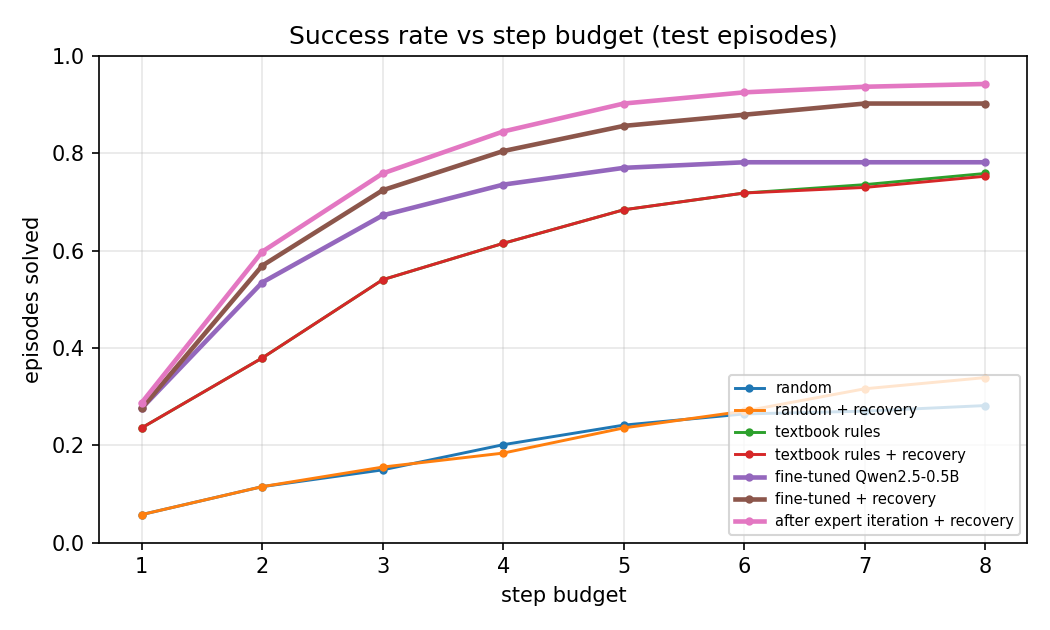

In [19]:
from IPython.display import Image, display
display(Image(str(paths.REPO_ROOT / "results" / "figures" / "phase4_success_vs_budget.png")))